# LLM, RAG i architektura agentowa

Notebook prezentuje warstwę wiedzy i wspomagania analizy
w systemie Financial Decision Support System.

Celem nie jest stworzenie autonomicznego chatbota,
lecz kontrolowanego asystenta analitycznego opartego na:

- ustrukturyzowanych wynikach finansowych;
- zweryfikowanych dokumentach źródłowych;
- retrievalu opartego na dowodach;
- transparentnych podsumowaniach analitycznych.

System wykorzystuje Retrieval-Augmented Generation (RAG),
aby ograniczyć odpowiedzi nieoparte na źródłach
i umożliwić wskazanie pochodzenia informacji.

Warstwa agentowa została zaprojektowana jako ograniczony workflow
z wyspecjalizowanymi rolami, a nie jako autonomiczny system wielu agentów.

## 1. Przepływ RAG

Zaimplementowany pipeline RAG obejmuje:

1. wczytywanie dokumentów;
2. dzielenie treści na fragmenty;
3. generowanie embeddingów;
4. retrieval wektorowy;
5. retrieval leksykalny;
6. ranking hybrydowy;
7. opcjonalny reranking;
8. generowanie odpowiedzi z cytowaniami.

Benchmark porównuje strategie retrievalu
przed analizą warstwy generacyjnej.

In [1]:
import json
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


RAG_RESULTS = PROJECT_ROOT / "benchmark_results" / "rag"

RAG_DATA = PROJECT_ROOT / "data" / "rag" / "evaluation"


print("Katalog projektu:")
print(PROJECT_ROOT)

print("\nWyniki RAG:")
for path in sorted(RAG_RESULTS.rglob("*")):
    if path.is_file():
        print(path)

Katalog projektu:
project-root

Wyniki RAG:
benchmark_results/rag/comparison.json
benchmark_results/rag/hybrid/benchmark.csv
benchmark_results/rag/hybrid/benchmark.json
benchmark_results/rag/reranked/benchmark.csv
benchmark_results/rag/reranked/benchmark.json
benchmark_results/rag/vector/benchmark.csv
benchmark_results/rag/vector/benchmark.json


## 2. Przygotowanie benchmarku RAG

W systemie porównywane są trzy strategie wyszukiwania:

### Vector Retrieval

Wyszukiwanie wykorzystujące podobieństwo semantyczne
pomiędzy embeddingiem pytania i fragmentami dokumentów.

Zalety:

- rozumie znaczenie pytania;
- działa dla różnych sformułowań tego samego problemu.

Ograniczenia:

- może pomijać dokładne dopasowania słów kluczowych.

### Hybrid Retrieval

Łączy:

- wyszukiwanie wektorowe;
- wyszukiwanie leksykalne BM25.

Celem jest połączenie rozumienia semantycznego
z dokładnością dopasowania tekstowego.

### Reranked Retrieval

Dodaje dodatkową warstwę rankingu,
która ponownie ocenia znalezione fragmenty.

Celem jest zwiększenie trafności
najważniejszych dokumentów przekazywanych do generatora odpowiedzi.

In [2]:
comparison_path = RAG_RESULTS / "comparison.json"

comparison = json.loads(comparison_path.read_text(encoding="utf-8"))

print(comparison.keys())

dict_keys(['best_configuration', 'ranking'])


In [3]:
comparison

{'best_configuration': 'vector',
 'ranking': [{'rank': 1,
   'configuration_name': 'vector',
   'quality_score': 0.8173076923076923,
   'item_count': 13,
   'mean_recall_at_k': 1.0,
   'mean_precision_at_k': 0.2692307692307692,
   'mean_hit_rate': 1.0,
   'mean_reciprocal_rank': 1.0,
   'mean_faithfulness': None,
   'mean_context_recall': None,
   'duration_seconds': 25.509833624993917},
  {'rank': 2,
   'configuration_name': 'hybrid',
   'quality_score': 0.8173076923076923,
   'item_count': 13,
   'mean_recall_at_k': 1.0,
   'mean_precision_at_k': 0.2692307692307692,
   'mean_hit_rate': 1.0,
   'mean_reciprocal_rank': 1.0,
   'mean_faithfulness': None,
   'mean_context_recall': None,
   'duration_seconds': 20.63469370797975},
  {'rank': 3,
   'configuration_name': 'reranked',
   'quality_score': 0.8173076923076923,
   'item_count': 13,
   'mean_recall_at_k': 1.0,
   'mean_precision_at_k': 0.2692307692307692,
   'mean_hit_rate': 1.0,
   'mean_reciprocal_rank': 1.0,
   'mean_faithfulnes

## 3. Wczytanie wyników poszczególnych strategii

Każda konfiguracja posiada zapisany benchmark
w formacie JSON oraz CSV.

JSON zawiera podsumowanie eksperymentu,
natomiast CSV pozwala analizować pojedyncze pytania.

In [4]:
strategies = [
    "vector",
    "hybrid",
    "reranked",
]

benchmark_results = {}

for strategy in strategies:
    path = RAG_RESULTS / strategy / "benchmark.json"

    benchmark_results[strategy] = json.loads(path.read_text(encoding="utf-8"))

    print(strategy, "załadowano")

vector załadowano
hybrid załadowano
reranked załadowano


In [5]:
for strategy, result in benchmark_results.items():
    print("\n---", strategy, "---")

    print(result.keys())


--- vector ---
dict_keys(['configuration_name', 'summary', 'items'])

--- hybrid ---
dict_keys(['configuration_name', 'summary', 'items'])

--- reranked ---
dict_keys(['configuration_name', 'summary', 'items'])


## 4. Zestawienie wyników benchmarku

Pierwszym krokiem jest porównanie ogólnych wyników
dla wszystkich strategii.

Pozwala to sprawdzić:

- czy dodanie warstwy hybrydowej poprawia retrieval;
- czy reranking zwiększa trafność;
- jaki jest koszt dodatkowej złożoności.

In [6]:
print(comparison)

{'best_configuration': 'vector', 'ranking': [{'rank': 1, 'configuration_name': 'vector', 'quality_score': 0.8173076923076923, 'item_count': 13, 'mean_recall_at_k': 1.0, 'mean_precision_at_k': 0.2692307692307692, 'mean_hit_rate': 1.0, 'mean_reciprocal_rank': 1.0, 'mean_faithfulness': None, 'mean_context_recall': None, 'duration_seconds': 25.509833624993917}, {'rank': 2, 'configuration_name': 'hybrid', 'quality_score': 0.8173076923076923, 'item_count': 13, 'mean_recall_at_k': 1.0, 'mean_precision_at_k': 0.2692307692307692, 'mean_hit_rate': 1.0, 'mean_reciprocal_rank': 1.0, 'mean_faithfulness': None, 'mean_context_recall': None, 'duration_seconds': 20.63469370797975}, {'rank': 3, 'configuration_name': 'reranked', 'quality_score': 0.8173076923076923, 'item_count': 13, 'mean_recall_at_k': 1.0, 'mean_precision_at_k': 0.2692307692307692, 'mean_hit_rate': 1.0, 'mean_reciprocal_rank': 1.0, 'mean_faithfulness': None, 'mean_context_recall': None, 'duration_seconds': 22.230288334016223}]}


In [7]:
for strategy, result in benchmark_results.items():
    print("\n---", strategy, "---")
    print(result)


--- vector ---
{'configuration_name': 'vector', 'summary': {'item_count': 13, 'mean_recall_at_k': 1.0, 'mean_precision_at_k': 0.2692307692307692, 'mean_hit_rate': 1.0, 'mean_reciprocal_rank': 1.0, 'mean_faithfulness': None, 'mean_context_recall': None, 'duration_seconds': 25.509833624993917}, 'items': [{'item_id': 'inflation_definition_001', 'question': 'What is inflation?', 'answer': 'Inflation is a sustained increase in the general price level of goods and services in an economy.', 'retrieved_document_ids': ['inflation_basics', 'interest_rates', 'financial_risk', 'portfolio_diversification'], 'retrieved_chunk_ids': ['inflation_basics_chunk_0000', 'interest_rates_chunk_0000', 'financial_risk_chunk_0000', 'portfolio_diversification_chunk_0000'], 'recall_at_k': 1.0, 'precision_at_k': 0.25, 'hit_rate': 1.0, 'reciprocal_rank': 1.0, 'duration_seconds': 4.972968249989208, 'faithfulness': None, 'context_recall': None}, {'item_id': 'inflation_causes_001', 'question': 'What can cause inflatio

## 4. Porównanie strategii retrieval

Benchmark porównuje trzy konfiguracje wyszukiwania:

- Vector Retrieval;
- Hybrid Retrieval;
- Reranked Retrieval.

Oceniamy:

- trafność znalezionych dokumentów;
- pokrycie oczekiwanych wyników;
- kolejność zwracanych fragmentów;
- czas wykonania.

Wyższy wynik nie oznacza automatycznie lepszego rozwiązania
produkcyjnego. Należy również uwzględnić koszt obliczeniowy
oraz złożoność całego pipeline'u.

In [8]:
ranking = pd.DataFrame(comparison["ranking"])

ranking

,rank,configuration_name,quality_score,item_count,mean_recall_at_k,mean_precision_at_k,mean_hit_rate,mean_reciprocal_rank,mean_faithfulness,mean_context_recall,duration_seconds
0,1,vector,0.817308,13,1.0,0.269231,1.0,1.0,None,None,25.509834
1,2,hybrid,0.817308,13,1.0,0.269231,1.0,1.0,None,None,20.634694
2,3,reranked,0.817308,13,1.0,0.269231,1.0,1.0,None,None,22.230288


In [9]:
ranking_display = ranking[
    [
        "configuration_name",
        "quality_score",
        "mean_recall_at_k",
        "mean_precision_at_k",
        "mean_hit_rate",
        "mean_reciprocal_rank",
        "duration_seconds",
    ]
].copy()


ranking_display.columns = [
    "Konfiguracja",
    "Quality score",
    "Recall@k",
    "Precision@k",
    "Hit rate",
    "MRR",
    "Czas [s]",
]


ranking_display

,Konfiguracja,Quality score,Recall@k,Precision@k,Hit rate,MRR,Czas [s]
0,vector,0.817308,1.0,0.269231,1.0,1.0,25.509834
1,hybrid,0.817308,1.0,0.269231,1.0,1.0,20.634694
2,reranked,0.817308,1.0,0.269231,1.0,1.0,22.230288


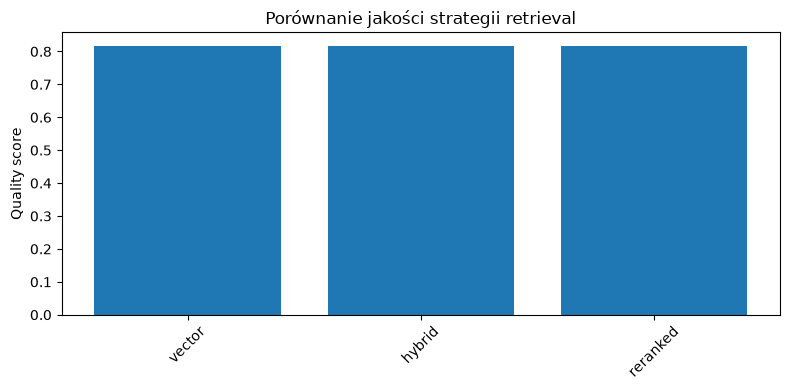

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.bar(
    ranking_display["Konfiguracja"],
    ranking_display["Quality score"],
)

plt.ylabel("Quality score")

plt.title("Porównanie jakości strategii retrieval")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

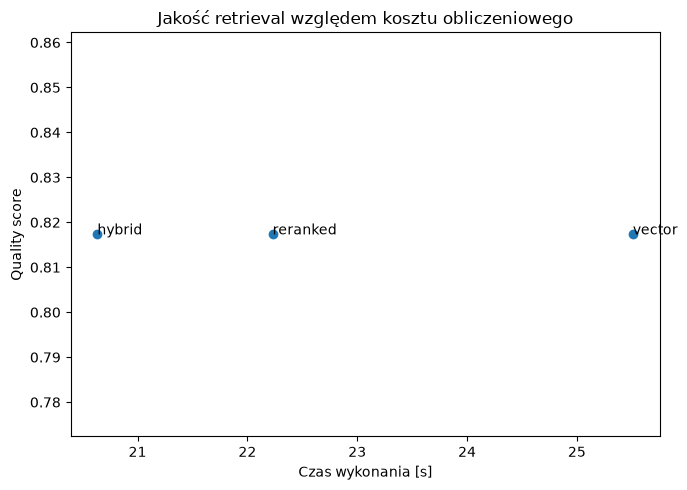

In [11]:
plt.figure(figsize=(7, 5))

plt.scatter(
    ranking_display["Czas [s]"],
    ranking_display["Quality score"],
)

for _, row in ranking_display.iterrows():
    plt.annotate(
        row["Konfiguracja"],
        (
            row["Czas [s]"],
            row["Quality score"],
        ),
    )

plt.xlabel("Czas wykonania [s]")

plt.ylabel("Quality score")

plt.title("Jakość retrieval względem kosztu obliczeniowego")

plt.tight_layout()

plt.show()

## Wnioski z benchmarku retrieval

Wyniki pokazują, że zwiększenie złożoności pipeline'u
nie zawsze prowadzi do proporcjonalnego wzrostu jakości.

Wybór strategii powinien uwzględniać:

- jakość wyników;
- czas działania;
- koszt utrzymania;
- wymagania aplikacji.

W systemie wspomagania decyzji finansowych ważna jest
równowaga pomiędzy trafnością, przejrzystością i
powtarzalnością działania.

## 5. Analiza przykładowych zapytań i znalezionych fragmentów

Poza metrykami agregowanymi ważna jest analiza pojedynczych przypadków.

Sprawdzamy:

- jakie pytania zostały użyte w benchmarku;
- jakie dokumenty zostały znalezione;
- jakie fragmenty otrzymały najwyższy ranking;
- czy zwrócone źródła odpowiadają tematowi pytania.

Taka analiza pozwala wykryć problemy,
które mogą nie być widoczne w samych metrykach liczbowych.

In [12]:
golden_path = RAG_DATA / "golden_dataset_expanded.json"

golden_dataset = json.loads(golden_path.read_text(encoding="utf-8"))

print(type(golden_dataset))

print(len(golden_dataset))

<class 'dict'>
1


In [13]:
golden_items = golden_dataset["items"]

questions = pd.DataFrame(golden_items)

questions.head()

,item_id,question,expected_document_ids,expected_chunk_ids,expected_keywords,reference_answer
0,inflation_definition_001,What is inflation?,[inflation_basics],[inflation_basics_chunk_0000],"[price level, goods, services]",Inflation is a sustained increase in the gener...
1,inflation_causes_001,What can cause inflation?,[inflation_basics],[inflation_basics_chunk_0000],"[aggregate demand, production costs, demand-pu...",Inflation may be caused by aggregate demand gr...
2,interest_rate_policy_001,Why may a central bank raise interest rates?,"[interest_rates, inflation_basics]","[interest_rates_chunk_0000, inflation_basics_c...","[reduce demand, inflationary pressure, inflation]",A central bank may raise interest rates to red...
3,financial_risk_types_001,What are the main types of financial risk desc...,[financial_risk],[financial_risk_chunk_0000],"[market risk, credit risk, liquidity risk]","The corpus describes market risk, credit risk,..."
4,diversification_001,How does portfolio diversification reduce risk?,[portfolio_diversification],[portfolio_diversification_chunk_0000],"[different assets, asset-specific risk, system...",Diversification reduces asset-specific risk by...


In [14]:
golden_dataset["items"][0]

{'item_id': 'inflation_definition_001',
 'question': 'What is inflation?',
 'expected_document_ids': ['inflation_basics'],
 'expected_chunk_ids': ['inflation_basics_chunk_0000'],
 'expected_keywords': ['price level', 'goods', 'services'],
 'reference_answer': 'Inflation is a sustained increase in the general price level of goods and services in an economy.'}

In [15]:
questions.columns

Index(['item_id', 'question', 'expected_document_ids', 'expected_chunk_ids',
       'expected_keywords', 'reference_answer'],
      dtype='str')

## Przykładowe pytania benchmarkowe

Zbiór ewaluacyjny zawiera ręcznie przygotowane pytania,
które reprezentują typowe potrzeby użytkownika systemu.

Pytania służą do sprawdzenia:

- czy system odnajduje właściwe informacje;
- czy źródła są zgodne z pytaniem;
- czy odpowiedzi mogą zostać uzupełnione cytowaniami.

In [16]:
vector_results = pd.read_csv(RAG_RESULTS / "vector" / "benchmark.csv")

vector_results.head()

,item_id,question,answer,retrieved_document_ids,retrieved_chunk_ids,recall_at_k,precision_at_k,hit_rate,reciprocal_rank,duration_seconds,faithfulness,context_recall
0,inflation_definition_001,What is inflation?,Inflation is a sustained increase in the gener...,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25,1.0,1.0,4.972968,NaN,NaN
1,inflation_causes_001,What can cause inflation?,"According to the context, inflation may occur ...","('inflation_basics', 'financial_risk', 'intere...","('inflation_basics_chunk_0000', 'financial_ris...",1.0,0.25,1.0,1.0,2.494026,NaN,NaN
2,interest_rate_policy_001,Why may a central bank raise interest rates?,A central bank may raise its policy interest r...,"('interest_rates', 'inflation_basics', 'financ...","('interest_rates_chunk_0000', 'inflation_basic...",1.0,0.50,1.0,1.0,1.855636,NaN,NaN
3,financial_risk_types_001,What are the main types of financial risk desc...,"According to the provided context, the main ty...","('financial_risk', 'portfolio_diversification'...","('financial_risk_chunk_0000', 'portfolio_diver...",1.0,0.25,1.0,1.0,1.777397,NaN,NaN
4,diversification_001,How does portfolio diversification reduce risk?,Portfolio diversification means allocating inv...,"('portfolio_diversification', 'financial_risk'...","('portfolio_diversification_chunk_0000', 'fina...",1.0,0.25,1.0,1.0,2.203174,NaN,NaN


In [17]:
vector_results.columns

Index(['item_id', 'question', 'answer', 'retrieved_document_ids',
       'retrieved_chunk_ids', 'recall_at_k', 'precision_at_k', 'hit_rate',
       'reciprocal_rank', 'duration_seconds', 'faithfulness',
       'context_recall'],
      dtype='str')

In [18]:
hybrid_results = pd.read_csv(RAG_RESULTS / "hybrid" / "benchmark.csv")

hybrid_results.head()

,item_id,question,answer,retrieved_document_ids,retrieved_chunk_ids,recall_at_k,precision_at_k,hit_rate,reciprocal_rank,duration_seconds,faithfulness,context_recall
0,inflation_definition_001,What is inflation?,Inflation is a sustained increase in the gener...,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25,1.0,1.0,1.553180,NaN,NaN
1,inflation_causes_001,What can cause inflation?,"According to the context, inflation may occur ...","('inflation_basics', 'financial_risk', 'intere...","('inflation_basics_chunk_0000', 'financial_ris...",1.0,0.25,1.0,1.0,1.694668,NaN,NaN
2,interest_rate_policy_001,Why may a central bank raise interest rates?,A central bank may raise its policy interest r...,"('interest_rates', 'inflation_basics', 'financ...","('interest_rates_chunk_0000', 'inflation_basic...",1.0,0.50,1.0,1.0,1.238166,NaN,NaN
3,financial_risk_types_001,What are the main types of financial risk desc...,"According to the provided text, the main types...","('financial_risk', 'interest_rates', 'portfoli...","('financial_risk_chunk_0000', 'interest_rates_...",1.0,0.25,1.0,1.0,1.803046,NaN,NaN
4,diversification_001,How does portfolio diversification reduce risk?,Portfolio diversification means allocating inv...,"('portfolio_diversification', 'financial_risk'...","('portfolio_diversification_chunk_0000', 'fina...",1.0,0.25,1.0,1.0,2.207487,NaN,NaN


In [19]:
reranked_results = pd.read_csv(RAG_RESULTS / "reranked" / "benchmark.csv")

reranked_results.head()

,item_id,question,answer,retrieved_document_ids,retrieved_chunk_ids,recall_at_k,precision_at_k,hit_rate,reciprocal_rank,duration_seconds,faithfulness,context_recall
0,inflation_definition_001,What is inflation?,Inflation is a sustained increase in the gener...,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25,1.0,1.0,1.852517,NaN,NaN
1,inflation_causes_001,What can cause inflation?,"According to the context, inflation may occur ...","('inflation_basics', 'financial_risk', 'intere...","('inflation_basics_chunk_0000', 'financial_ris...",1.0,0.25,1.0,1.0,2.055950,NaN,NaN
2,interest_rate_policy_001,Why may a central bank raise interest rates?,A central bank may raise its policy interest r...,"('interest_rates', 'inflation_basics', 'financ...","('interest_rates_chunk_0000', 'inflation_basic...",1.0,0.50,1.0,1.0,1.414652,NaN,NaN
3,financial_risk_types_001,What are the main types of financial risk desc...,The main types of financial risk described in ...,"('financial_risk', 'portfolio_diversification'...","('financial_risk_chunk_0000', 'portfolio_diver...",1.0,0.25,1.0,1.0,1.824975,NaN,NaN
4,diversification_001,How does portfolio diversification reduce risk?,Portfolio diversification means allocating inv...,"('portfolio_diversification', 'financial_risk'...","('portfolio_diversification_chunk_0000', 'fina...",1.0,0.25,1.0,1.0,2.261576,NaN,NaN


In [20]:
print("Vector:")
print(vector_results.columns.tolist())

print("\nHybrid:")
print(hybrid_results.columns.tolist())

print("\nReranked:")
print(reranked_results.columns.tolist())

Vector:
['item_id', 'question', 'answer', 'retrieved_document_ids', 'retrieved_chunk_ids', 'recall_at_k', 'precision_at_k', 'hit_rate', 'reciprocal_rank', 'duration_seconds', 'faithfulness', 'context_recall']

Hybrid:
['item_id', 'question', 'answer', 'retrieved_document_ids', 'retrieved_chunk_ids', 'recall_at_k', 'precision_at_k', 'hit_rate', 'reciprocal_rank', 'duration_seconds', 'faithfulness', 'context_recall']

Reranked:
['item_id', 'question', 'answer', 'retrieved_document_ids', 'retrieved_chunk_ids', 'recall_at_k', 'precision_at_k', 'hit_rate', 'reciprocal_rank', 'duration_seconds', 'faithfulness', 'context_recall']


In [21]:
example_id = "inflation_definition_001"

vector_example = vector_results[vector_results["item_id"] == example_id]

hybrid_example = hybrid_results[hybrid_results["item_id"] == example_id]

reranked_example = reranked_results[reranked_results["item_id"] == example_id]


display(
    vector_example[
        [
            "item_id",
            "question",
            "retrieved_document_ids",
            "retrieved_chunk_ids",
            "recall_at_k",
            "precision_at_k",
            "reciprocal_rank",
        ]
    ]
)

display(
    hybrid_example[
        [
            "item_id",
            "question",
            "retrieved_document_ids",
            "retrieved_chunk_ids",
            "recall_at_k",
            "precision_at_k",
            "reciprocal_rank",
        ]
    ]
)

display(
    reranked_example[
        [
            "item_id",
            "question",
            "retrieved_document_ids",
            "retrieved_chunk_ids",
            "recall_at_k",
            "precision_at_k",
            "reciprocal_rank",
        ]
    ]
)

,item_id,question,retrieved_document_ids,retrieved_chunk_ids,recall_at_k,precision_at_k,reciprocal_rank
0,inflation_definition_001,What is inflation?,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25,1.0


,item_id,question,retrieved_document_ids,retrieved_chunk_ids,recall_at_k,precision_at_k,reciprocal_rank
0,inflation_definition_001,What is inflation?,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25,1.0


,item_id,question,retrieved_document_ids,retrieved_chunk_ids,recall_at_k,precision_at_k,reciprocal_rank
0,inflation_definition_001,What is inflation?,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25,1.0


In [22]:
display(vector_example[["question", "answer"]])

display(hybrid_example[["question", "answer"]])

display(reranked_example[["question", "answer"]])

,question,answer
0,What is inflation?,Inflation is a sustained increase in the gener...


,question,answer
0,What is inflation?,Inflation is a sustained increase in the gener...


,question,answer
0,What is inflation?,Inflation is a sustained increase in the gener...


In [23]:
comparison = pd.DataFrame(
    {
        "strategy": [
            "vector",
            "hybrid",
            "reranked",
        ],
        "retrieved_document_ids": [
            vector_example.iloc[0]["retrieved_document_ids"],
            hybrid_example.iloc[0]["retrieved_document_ids"],
            reranked_example.iloc[0]["retrieved_document_ids"],
        ],
        "retrieved_chunk_ids": [
            vector_example.iloc[0]["retrieved_chunk_ids"],
            hybrid_example.iloc[0]["retrieved_chunk_ids"],
            reranked_example.iloc[0]["retrieved_chunk_ids"],
        ],
        "recall_at_k": [
            vector_example.iloc[0]["recall_at_k"],
            hybrid_example.iloc[0]["recall_at_k"],
            reranked_example.iloc[0]["recall_at_k"],
        ],
        "precision_at_k": [
            vector_example.iloc[0]["precision_at_k"],
            hybrid_example.iloc[0]["precision_at_k"],
            reranked_example.iloc[0]["precision_at_k"],
        ],
    }
)

comparison

,strategy,retrieved_document_ids,retrieved_chunk_ids,recall_at_k,precision_at_k
0,vector,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25
1,hybrid,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25
2,reranked,"('inflation_basics', 'interest_rates', 'financ...","('inflation_basics_chunk_0000', 'interest_rate...",1.0,0.25


In [24]:
reranked_example[
    [
        "question",
        "retrieved_chunk_ids",
        "reciprocal_rank",
        "faithfulness",
        "context_recall",
    ]
]

,question,retrieved_chunk_ids,reciprocal_rank,faithfulness,context_recall
0,What is inflation?,"('inflation_basics_chunk_0000', 'interest_rate...",1.0,NaN,NaN


### Interpretacja przykładu

Dla pytania **"What is inflation?"** wszystkie trzy strategie retrieval
odnalazły właściwy dokument na pierwszej pozycji.

W analizowanym przypadku:

- `recall@k = 1.0`;
- `reciprocal rank = 1.0`;
- wszystkie konfiguracje zwróciły właściwy fragment `inflation_basics`;
- reranking nie zmienił jakości wyniku względem prostszego retrievalu.

Brak wartości `faithfulness` i `context_recall` nie oznacza błędu pipeline'u.
Są to opcjonalne metryki oceniane przez dodatkową warstwę LLM-judge,
która nie była używana w tym benchmarku.

Wynik pokazuje, że na obecnym małym i kontrolowanym korpusie
bardziej złożone strategie retrieval nie zapewniają mierzalnej przewagi
nad konfiguracją wektorową.

## 6. Wnioski z ewaluacji RAG

Benchmark obejmuje 13 ręcznie przygotowanych pytań oraz trzy strategie
wyszukiwania: Vector, Hybrid i Reranked.

Najważniejsze wyniki:

- wszystkie konfiguracje osiągnęły `recall@k = 1.0`;
- hit rate wyniósł `1.0`;
- MRR wyniósł `1.0`;
- quality score był identyczny dla wszystkich konfiguracji;
- zwiększenie złożoności retrievalu nie poprawiło jakości na obecnym korpusie;
- różnice pomiędzy strategiami dotyczą obecnie głównie czasu wykonania.

Wynik należy interpretować ostrożnie, ponieważ obecny korpus i golden dataset
są niewielkie i służą przede wszystkim do rozwoju systemu.

Szersza ocena RAG zostanie wykonana dopiero podczas finalnego etapu ewaluacji.

## 7. Architektura agentowa

Warstwa agentowa wykorzystuje wyniki istniejących modułów analitycznych
oraz wiedzę dostarczaną przez RAG.

Agenci nie wykonują ponownie obliczeń finansowych i nie zastępują
deterministycznych usług backendu. Ich rolą jest interpretacja
ustrukturyzowanych wyników oraz przygotowanie czytelnego podsumowania.

W systemie dostępne są trzy wyspecjalizowane workflow:

- **Forecast Agent** — interpretuje wyniki prognoz i jakość modeli;
- **Risk Agent** — interpretuje miary ryzyka i scenariusze;
- **Allocation Agent** — interpretuje strategie alokacji portfela.

Podejście celowo ogranicza autonomię agentów i wymaga zachowania
traceable evidence oraz jawnych ograniczeń.

In [ ]:
AGENT_RESULTS = PROJECT_ROOT / "benchmark_results" / "agents" / "agent_results.json"

agent_results = json.loads(AGENT_RESULTS.read_text(encoding="utf-8"))

agent_metadata = pd.DataFrame(
    [
        {
            "Model": agent_results["model_name"],
            "Strategia retrieval": agent_results["retrieval_strategy"],
            "Podstawa ewaluacji": agent_results["evaluation_basis"],
            "Test split użyty": agent_results["test_split_used"],
        }
    ]
)

display(agent_metadata)

,Model,Strategia retrieval,Podstawa ewaluacji,Test split użyty
0,gemma3:4b,vector,validation_benchmark_artifacts,False


In [26]:
assert agent_results["test_split_used"] is False

print(
    "Końcowy test split pozostaje zamknięty "
    "i nie został wykorzystany przez warstwę agentową."
)

Końcowy test split pozostaje zamknięty i nie został wykorzystany przez warstwę agentową.


## 8. Forecast Agent

Forecast Agent interpretuje wyniki modułu prognostycznego oraz
informacje z warstwy explainability.

Jego zadaniem nie jest ponowne trenowanie modelu ani generowanie
nowych prognoz, lecz interpretacja istniejących wyników benchmarkowych.

Agent powinien zwracać:

- syntetyczne podsumowanie;
- najważniejsze ustalenia;
- ryzyka interpretacyjne;
- rekomendacje dotyczące sposobu użycia prognozy;
- ograniczenia;
- źródła wykorzystanych informacji.

In [27]:
forecast_agent = agent_results["responses"]["forecast"]

print("Agent:")
print(forecast_agent["agent_name"])

print("\nPytanie:")
print(forecast_agent["question"])

print("\nPodsumowanie:")
print(forecast_agent["summary"])

Agent:
forecast_analysis_agent

Pytanie:
Jak wiarygodny jest model Random Forest i które cechy mają największy wpływ na jego prognozy?

Podsumowanie:
Model Random Forest ma na walidacji słabą zdolność prognostyczną: R²=0.0048, a trafność kierunku wynosi 50.48%.


In [28]:
forecast_sections = {
    "Ustalenia": forecast_agent["findings"],
    "Ryzyka": forecast_agent["risks"],
    "Rekomendacje": forecast_agent["recommendations"],
    "Ograniczenia": forecast_agent["limitations"],
}

for section_name, items in forecast_sections.items():
    print(f"\n{section_name}:")

    for item in items:
        print("-", item)


Ustalenia:
- Ocena obejmuje 4786 obserwacji; MAE=0.011043, RMSE=0.016901.
- Najważniejsze globalne cechy według średniej bezwzględnej wartości SHAP to: adjusted_close_to_ma_20, momentum_20, adjusted_close_to_ma_5, open_to_close_return.
- Wartości SHAP opisują sposób działania modelu, lecz nie dowodzą zależności przyczynowej.

Ryzyka:
- Trafność kierunku bliska 50% oznacza, że prognoza nie powinna być samodzielną podstawą alokacji.
- Zmiana reżimu rynkowego może pogorszyć wyniki względem zaobserwowanej walidacji.

Rekomendacje:
- Traktuj prognozę jako sygnał pomocniczy i łącz ją z limitami ryzyka oraz analizą portfela.
- Monitoruj błędy i trafność kierunku osobno dla każdego tickera przed wykorzystaniem operacyjnym.

Ograniczenia:
- Metryki pochodzą ze zbioru walidacyjnego, a nie z przyszłości.
- Interpretacje SHAP opisują model Random Forest i nie są dowodem ekonomicznej przyczynowości.
- Wynik ma charakter wsparcia decyzyjnego opartego na danych historycznych; nie jest indywidualną p

In [ ]:
forecast_evidence = pd.DataFrame(forecast_agent["evidence"])

display(forecast_evidence)

,source_type,identifier,description
0,benchmark_artifact,forecast_result.json,Random Forest validation forecast metrics
1,benchmark_artifact,xai_result.json,Random Forest SHAP and feature effects
2,rag_document,financial_risk,reference_corpus/financial_risk
3,rag_document,portfolio_diversification,reference_corpus/portfolio_diversification
4,rag_document,interest_rates,reference_corpus/interest_rates
5,rag_document,inflation_basics,reference_corpus/inflation_basics


### Interpretacja Forecast Agent

Forecast Agent poprawnie zachowuje ostrożną interpretację wyników.

W szczególności:

- wskazuje bardzo niski współczynnik R²;
- zauważa, że trafność kierunku jest bliska 50%;
- nie przedstawia Random Forest jako wiarygodnego samodzielnego sygnału inwestycyjnego;
- sugeruje łączenie prognozy z kontrolą ryzyka i analizą portfela;
- jawnie informuje, że metryki dotyczą zbioru walidacyjnego.

Warstwa agentowa nie zastępuje oceny modelu, lecz syntetyzuje
istniejące wyniki i ich ograniczenia.

## 9. Risk Agent

Risk Agent interpretuje wyniki modułu ryzyka oraz porównanie
scenariuszy portfelowych.

Jego zadaniem jest wskazanie:

- najważniejszych różnic pomiędzy wariantami;
- kompromisów pomiędzy zwrotem i ryzykiem;
- ryzyka obsunięcia kapitału;
- znaczenia zmienności i współczynników risk-adjusted return;
- ograniczeń wynikających z walidacyjnego charakteru analizy.

In [30]:
risk_agent = agent_results["responses"]["risk"]

print("Agent:")
print(risk_agent["agent_name"])

print("\nPytanie:")
print(risk_agent["question"])

print("\nPodsumowanie:")
print(risk_agent["summary"])

Agent:
risk_analysis_agent

Pytanie:
Jakie są najważniejsze różnice ryzyka pomiędzy ocenionymi wariantami portfela?

Podsumowanie:
Porównano 5 scenariuszy na walidacji. Najniższą zmienność ma minimum_volatility, a najwyższy Sharpe ma maximum_sharpe.


In [31]:
risk_sections = {
    "Ustalenia": risk_agent["findings"],
    "Ryzyka": risk_agent["risks"],
    "Rekomendacje": risk_agent["recommendations"],
    "Ograniczenia": risk_agent["limitations"],
}

for section_name, items in risk_sections.items():
    print(f"\n{section_name}:")

    for item in items:
        print("-", item)


Ustalenia:
- minimum_volatility osiąga roczną zmienność 9.51%.
- minimum_volatility ma najniższy maksymalny drawdown: 15.31%.
- maximum_sharpe osiąga najwyższy współczynnik Sharpe: 0.5846.

Ryzyka:
- Wyższy oczekiwany zwrot wiąże się w ocenionych wariantach z większą zmiennością lub obsunięciem kapitału.
- VaR i CVaR opisują historyczny ogon rozkładu i mogą niedoszacować nowych zdarzeń skrajnych.

Rekomendacje:
- Wybieraj scenariusz według jawnego celu: ograniczenia zmienności, obsunięcia albo maksymalizacji Sharpe’a.
- Kontroluj koncentrację i dywersyfikację razem z VaR, CVaR i maksymalnym drawdownem.

Ograniczenia:
- Porównanie opisuje historyczny okres walidacyjny.
- Metryki ryzyka nie obejmują wszystkich przyszłych scenariuszy.
- Wynik ma charakter wsparcia decyzyjnego opartego na danych historycznych; nie jest indywidualną poradą finansową ani gwarancją przyszłych rezultatów.


In [ ]:
risk_evidence = pd.DataFrame(risk_agent["evidence"])

display(risk_evidence)

,source_type,identifier,description
0,benchmark_artifact,portfolio_result.json,Training-constructed portfolio scenarios evalu...
1,rag_document,portfolio_diversification,reference_corpus/portfolio_diversification
2,rag_document,financial_risk,reference_corpus/financial_risk
3,rag_document,interest_rates,reference_corpus/interest_rates
4,rag_document,inflation_basics,reference_corpus/inflation_basics


### Interpretacja Risk Agent

Risk Agent poprawnie rozróżnia cele poszczególnych strategii.

W szczególności:

- wskazuje wariant `minimum_volatility` jako rozwiązanie o najniższej zmienności;
- identyfikuje `maximum_sharpe` jako strategię o najwyższym współczynniku Sharpe;
- nie traktuje najwyższego zwrotu jako automatycznie najlepszego rozwiązania;
- podkreśla kompromis pomiędzy zwrotem, zmiennością i obsunięciem kapitału;
- jawnie wskazuje, że porównanie dotyczy okresu walidacyjnego.

Agent wspiera interpretację profilu ryzyka, ale nie zastępuje
formalnych metryk portfelowych ani indywidualnej oceny tolerancji ryzyka.

## 10. Allocation Agent

Allocation Agent interpretuje wyniki strategii alokacji portfela
i zestawia klasyczne podejścia z eksperymentalnym agentem PPO.

Jego zadaniem jest:

- wskazanie strategii referencyjnej dla określonego profilu ryzyka;
- porównanie zwrotu, zmienności, Sharpe i drawdown;
- ocena, czy rozwiązanie RL wnosi mierzalną przewagę;
- przedstawienie ograniczeń interpretacyjnych;
- zachowanie ostrożnego charakteru rekomendacji.

Agent nie podejmuje automatycznej decyzji inwestycyjnej.

In [33]:
allocation_agent = agent_results["responses"]["allocation"]

print("Agent:")
print(allocation_agent["agent_name"])

print("\nPytanie:")
print(allocation_agent["question"])

print("\nPodsumowanie:")
print(allocation_agent["summary"])

Agent:
allocation_recommendation_agent

Pytanie:
Który oceniony wariant najlepiej równoważy zwrot i ryzyko oraz jak PPO wypada na tle metod klasycznych?

Podsumowanie:
Dla profilu balanced wariantem referencyjnym jest maximum_sharpe. PPO nie osiągnęło ani najwyższego zwrotu, ani najwyższego współczynnika Sharpe na walidacji.


In [34]:
allocation_sections = {
    "Ustalenia": allocation_agent["findings"],
    "Ryzyka": allocation_agent["risks"],
    "Rekomendacje": allocation_agent["recommendations"],
    "Ograniczenia": allocation_agent["limitations"],
}

for section_name, items in allocation_sections.items():
    print(f"\n{section_name}:")

    for item in items:
        print("-", item)


Ustalenia:
- Najwyższy roczny zwrot osiąga equal_weight: 12.08%.
- Najwyższy Sharpe osiąga maximum_sharpe: 0.5657.
- Najniższą zmienność ma minimum_volatility: 9.51%; najniższy drawdown ma minimum_volatility: 15.31%.

Ryzyka:
- Ranking zależy od celu: zwrot, Sharpe, zmienność i drawdown wskazują różne warianty.
- Dynamiczna polityka PPO uwzględnia koszty transakcyjne, ale jej wynik walidacyjny nie dowodzi przewagi nad strategiami klasycznymi.

Rekomendacje:
- Dla profilu balanced traktuj maximum_sharpe jako wariant referencyjny do dalszej analizy, nie jako automatyczną decyzję inwestycyjną.
- Przed końcowym wyborem porównaj tolerowany drawdown, zmienność, koncentrację oraz koszty zmian alokacji.

Ograniczenia:
- Porównanie opiera się na wynikach walidacyjnych.
- Końcowy zbiór testowy nie został wykorzystany i pozostaje zamknięty.
- Wynik ma charakter wsparcia decyzyjnego opartego na danych historycznych; nie jest indywidualną poradą finansową ani gwarancją przyszłych rezultatów.


In [ ]:
allocation_evidence = pd.DataFrame(allocation_agent["evidence"])

display(allocation_evidence)

,source_type,identifier,description
0,benchmark_artifact,portfolio_result.json,Classical and manual portfolio validation results
1,benchmark_artifact,rl_result.json,PPO and classical strategy validation comparison
2,rag_document,portfolio_diversification,reference_corpus/portfolio_diversification
3,rag_document,financial_risk,reference_corpus/financial_risk
4,rag_document,interest_rates,reference_corpus/interest_rates
5,rag_document,inflation_basics,reference_corpus/inflation_basics


### Interpretacja Allocation Agent

Allocation Agent poprawnie zachowuje zależność pomiędzy celem inwestycyjnym
a wyborem strategii.

W szczególności:

- nie wskazuje jednej strategii jako bezwarunkowo najlepszej;
- traktuje `maximum_sharpe` jako wariant referencyjny dla profilu balanced;
- zauważa, że `equal_weight` osiąga najwyższy roczny zwrot w porównaniu walidacyjnym;
- wskazuje, że PPO nie uzyskało najwyższego zwrotu ani najwyższego Sharpe;
- podkreśla, że ranking zależy od wybranego kryterium oceny;
- jawnie zaznacza, że analiza dotyczy danych walidacyjnych.

Wynik PPO jest interpretowany jako eksperymentalne rozszerzenie,
a nie jako automatycznie lepsza metoda od klasycznych strategii portfelowych.

Szczegółowa analiza środowiska RL, funkcji nagrody i wyników PPO
zostanie przedstawiona osobno w notebooku `06_reinforcement_learning.ipynb`.

## 11. Wnioski końcowe

Notebook pokazuje pełną warstwę LLM, RAG i agentów
w Financial Decision Support System.

Najważniejsze obserwacje:

- RAG wykorzystuje kontrolowany korpus i golden dataset;
- strategie Vector, Hybrid i Reranked osiągnęły identyczną jakość retrieval na obecnym zbiorze;
- bardziej złożony retrieval nie zapewnił mierzalnej przewagi jakościowej;
- warstwa agentowa interpretuje istniejące wyniki zamiast ponownie wykonywać obliczenia;
- Forecast Agent zachowuje ostrożność wobec słabej jakości prognostycznej;
- Risk Agent poprawnie rozróżnia profile ryzyka i kompromisy portfelowe;
- Allocation Agent nie traktuje PPO jako automatycznie lepszego rozwiązania;
- wszystkie odpowiedzi agentów zawierają jawne ograniczenia i evidence;
- końcowy test split pozostaje zamknięty.

Warstwa generatywna pełni funkcję interpretacyjną i wspomagającą.
Nie zastępuje deterministycznych modułów analitycznych ani formalnej oceny modeli.